In [ ]:
# Step 1: Start with $10,000,000, held entirely in cash.
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

data_dir = Path("data") if Path("data").is_dir() else Path("../data")
initial_cash = 10_000_000.0
display(pd.Series({"Initial cash ($)": initial_cash}).to_frame("Amount").style.format("{:,.2f}"))

,Amount
Initial cash ($),"10,000,000.00"


In [ ]:
# Step 2: Set transaction costs to 0.15% (15 basis points).
transaction_cost_rate = 15 / 10_000
print(f"Transaction cost rate: {transaction_cost_rate:.2%} (15 bps)")

Transaction cost rate: 0.15% (15 bps)


In [ ]:
# Step 3: Reserve $15,000 for estimated transaction costs.
estimated_transaction_cost = initial_cash * transaction_cost_rate
investable_cash = initial_cash - estimated_transaction_cost

display(pd.Series({
    "Estimated transaction costs ($)": estimated_transaction_cost,
    "Available for stock purchases ($)": investable_cash,
}).to_frame("Amount").style.format("{:,.2f}"))

,Amount
Estimated transaction costs ($),"15,000.00"
Available for stock purchases ($),"9,985,000.00"


In [ ]:
# Step 4: Multiply each Stage 3 weight by $9,985,000.
weights_path = data_dir / "Group3_Weights.xlsx"
stage3_weights = pd.read_excel(weights_path, index_col=0)["Stage 3"]
stage3_weights.index.name = "Ticker"
purchases = stage3_weights.rename("Stage 3 weight").to_frame()
purchases["Gross allocation ($)"] = stage3_weights * investable_cash

print(f"Weights source: {weights_path}")
print(f"Stage 3 weight total: {stage3_weights.sum():.3%}")
print(f"Unallocated before whole-share rounding: ${investable_cash - purchases['Gross allocation ($)'].sum():,.2f}")
display(purchases.style.format({"Stage 3 weight": "{:.3%}", "Gross allocation ($)": "{:,.2f}"}))

Weights source: data\Group3_Weights.xlsx
Stage 3 weight total: 99.999%
Unallocated before whole-share rounding: $99.85


,Stage 3 weight,Gross allocation ($)
Ticker,,
VST,0.100%,"9,985.00"
VIST,3.574%,"356,863.90"
AEP,5.976%,"596,703.60"
ETR,10.000%,"998,500.00"
DIS,0.100%,"9,985.00"
CMG,0.386%,"38,542.10"
AMZN,0.100%,"9,985.00"
FIX,0.100%,"9,985.00"
STX,0.100%,"9,985.00"


In [ ]:
# Step 5: Divide each gross allocation by its September 4, 2026 stock price.
# September 7 was Labor Day; use the preceding trading close.
valuation_date = pd.Timestamp("2026-09-07")
price_date = pd.Timestamp("2026-09-04")
price_path = data_dir / "WeeklyPrices_2026-09-04_to_2026-11-06.xlsx"
price_history = pd.read_excel(price_path, sheet_name="Weekly Prices", index_col="date").rename(
    columns={"BRK-B": "BRK.B"}
)
purchases["Stock price ($)"] = price_history.loc[price_date, purchases.index]
purchases["Fractional shares"] = purchases["Gross allocation ($)"] / purchases["Stock price ($)"]

print(f"Price source: {price_path}, sheet: Weekly Prices")
print(f"Valuation date: {valuation_date:%Y-%m-%d}; pricing date: {price_date:%Y-%m-%d} (preceding trading close)")
display(purchases[["Gross allocation ($)", "Stock price ($)", "Fractional shares"]].style.format("{:,.4f}"))

Price source: data\WeeklyPrices_2026-09-04_to_2026-11-06.xlsx, sheet: Weekly Prices
Valuation date: 2026-09-07; pricing date: 2026-09-04 (preceding trading close)


,Gross allocation ($),Stock price ($),Fractional shares
Ticker,,,
VST,"9,985.0000",149.0559,66.9883
VIST,"356,863.9000",73.7300,"4,840.1449"
AEP,"596,703.6000",124.5000,"4,792.8000"
ETR,"998,500.0000",107.2700,"9,308.2878"
DIS,"9,985.0000",105.3100,94.8153
CMG,"38,542.1000",36.9600,"1,042.8058"
AMZN,"9,985.0000",258.5100,38.6252
FIX,"9,985.0000","1,610.3400",6.2006
STX,"9,985.0000",848.5998,11.7664


In [ ]:
# Step 6: Round down to whole shares, then compute actual stock purchase costs.
purchases["Shares"] = np.floor(purchases["Fractional shares"]).astype("int64")
purchases["Purchase cost ($)"] = purchases["Shares"] * purchases["Stock price ($)"]
purchases["Unspent allocation ($)"] = purchases["Gross allocation ($)"] - purchases["Purchase cost ($)"]

display(purchases[["Stock price ($)", "Shares", "Purchase cost ($)", "Unspent allocation ($)"]].style.format({
    "Stock price ($)": "{:,.4f}", "Shares": "{:,}",
    "Purchase cost ($)": "{:,.2f}", "Unspent allocation ($)": "{:,.2f}",
}))

,Stock price ($),Shares,Purchase cost ($),Unspent allocation ($)
Ticker,,,,
VST,149.0559,66,"9,837.69",147.31
VIST,73.7300,"4,840","356,853.22",10.68
AEP,124.5000,"4,792","596,604.00",99.60
ETR,107.2700,"9,308","998,469.13",30.87
DIS,105.3100,94,"9,899.14",85.86
CMG,36.9600,"1,042","38,512.32",29.78
AMZN,258.5100,38,"9,823.38",161.62
FIX,"1,610.3400",6,"9,662.04",322.96
STX,848.5998,11,"9,334.60",650.40


In [ ]:
# Step 7: Compute actual transaction costs on the whole-share purchase values.
purchases["Actual transaction cost ($)"] = purchases["Purchase cost ($)"] * transaction_cost_rate
display(purchases[["Purchase cost ($)", "Actual transaction cost ($)"]].style.format("{:,.2f}"))

,Purchase cost ($),Actual transaction cost ($)
Ticker,,
VST,"9,837.69",14.76
VIST,"356,853.22",535.28
AEP,"596,604.00",894.91
ETR,"998,469.13","1,497.70"
DIS,"9,899.14",14.85
CMG,"38,512.32",57.77
AMZN,"9,823.38",14.74
FIX,"9,662.04",14.49
STX,"9,334.60",14.00


In [ ]:
# Step 8: Sum all stock purchase costs plus all actual transaction costs.
total_purchase_cost = purchases["Purchase cost ($)"].sum()
total_actual_transaction_cost = purchases["Actual transaction cost ($)"].sum()
total_outlay = total_purchase_cost + total_actual_transaction_cost

display(pd.Series({
    "Stock purchase costs ($)": total_purchase_cost,
    "Actual transaction costs ($)": total_actual_transaction_cost,
    "Total cash spent ($)": total_outlay,
}).to_frame("Amount").style.format("{:,.2f}"))

,Amount
Stock purchase costs ($),"9,978,363.35"
Actual transaction costs ($),"14,967.55"
Total cash spent ($),"9,993,330.89"


In [ ]:
# Step 9: Calculate remaining cash and add it as a portfolio holding.
cash_balance = initial_cash - total_outlay
portfolio = purchases[["Stage 3 weight", "Stock price ($)", "Shares", "Purchase cost ($)"]].rename(
    columns={"Purchase cost ($)": "Market value ($)"}
)
portfolio.loc["CASH"] = [0.0, np.nan, np.nan, cash_balance]
portfolio["Shares"] = portfolio["Shares"].astype("Int64")
portfolio_value = portfolio["Market value ($)"].sum()
portfolio["Portfolio weight"] = portfolio["Market value ($)"] / portfolio_value

print(f"Cash balance: ${cash_balance:,.2f}")
print(f"Portfolio value after actual transaction costs: ${portfolio_value:,.2f}")
print("Portfolio weights use the portfolio value after transaction costs.")
display(portfolio.style.format({
    "Stage 3 weight": "{:.3%}", "Stock price ($)": "{:,.4f}",
    "Shares": "{:,}", "Market value ($)": "{:,.2f}", "Portfolio weight": "{:.3%}",
}, na_rep=""))

Cash balance: $6,669.11
Portfolio value after actual transaction costs: $9,985,032.45
Portfolio weights use the portfolio value after transaction costs.


,Stage 3 weight,Stock price ($),Shares,Market value ($),Portfolio weight
Ticker,,,,,
VST,0.100%,149.0559,66,"9,837.69",0.099%
VIST,3.574%,73.7300,"4,840","356,853.22",3.574%
AEP,5.976%,124.5000,"4,792","596,604.00",5.975%
ETR,10.000%,107.2700,"9,308","998,469.13",10.000%
DIS,0.100%,105.3100,94,"9,899.14",0.099%
CMG,0.386%,36.9600,"1,042","38,512.32",0.386%
AMZN,0.100%,258.5100,38,"9,823.38",0.098%
FIX,0.100%,"1,610.3400",6,"9,662.04",0.097%
STX,0.100%,848.5998,11,"9,334.60",0.093%


In [10]:
# Implementation table using the current holdings and cash balance.
# Gross is before the fee reserve; net_available is the stock purchase budget.
implementation = pd.DataFrame({
    "weight": purchases["Stage 3 weight"],
    "gross_allocation": purchases["Stage 3 weight"] * initial_cash,
    "estimated_cost": purchases["Stage 3 weight"] * estimated_transaction_cost,
    "net_available": purchases["Gross allocation ($)"],
    f"price_{price_date:%Y-%m-%d}": purchases["Stock price ($)"],
    "shares": purchases["Shares"],
    f"stock_value_{price_date:%Y-%m-%d}": purchases["Purchase cost ($)"],
    "actual_transaction_cost": purchases["Actual transaction cost ($)"],
    "stock_plus_cost": purchases["Purchase cost ($)"] + purchases["Actual transaction cost ($)"],
    "cash": 0.0,
})
implementation.loc["Cash"] = 0
implementation.loc["Cash", "cash"] = cash_balance
implementation = implementation.rename_axis("ticker").reset_index()
display(implementation.style.hide(axis="index").format({
    **dict.fromkeys(implementation.columns[1:], "{:,.2f}"),
    "weight": "{:.6f}", "shares": "{:.0f}", f"price_{price_date:%Y-%m-%d}": "{:,.4f}",
}))


ticker,weight,gross_allocation,estimated_cost,net_available,price_2026-09-04,shares,stock_value_2026-09-04,actual_transaction_cost,stock_plus_cost,cash
VST,0.001000,"10,000.00",15.00,"9,985.00",149.0559,66,"9,837.69",14.76,"9,852.45",0.00
VIST,0.035740,"357,400.00",536.10,"356,863.90",73.7300,4840,"356,853.22",535.28,"357,388.50",0.00
AEP,0.059760,"597,600.00",896.40,"596,703.60",124.5000,4792,"596,604.00",894.91,"597,498.91",0.00
ETR,0.100000,"1,000,000.00","1,500.00","998,500.00",107.2700,9308,"998,469.13","1,497.70","999,966.83",0.00
DIS,0.001000,"10,000.00",15.00,"9,985.00",105.3100,94,"9,899.14",14.85,"9,913.99",0.00
CMG,0.003860,"38,600.00",57.90,"38,542.10",36.9600,1042,"38,512.32",57.77,"38,570.09",0.00
AMZN,0.001000,"10,000.00",15.00,"9,985.00",258.5100,38,"9,823.38",14.74,"9,838.12",0.00
FIX,0.001000,"10,000.00",15.00,"9,985.00","1,610.3400",6,"9,662.04",14.49,"9,676.53",0.00
STX,0.001000,"10,000.00",15.00,"9,985.00",848.5998,11,"9,334.60",14.00,"9,348.60",0.00
VLO,0.001000,"10,000.00",15.00,"9,985.00",370.7200,26,"9,638.72",14.46,"9,653.18",0.00


In [10]:
# Step 10: Value the fixed stock holdings and cash weekly through October 30.
# Keep shares and cash unchanged; assume no cash interest or further trades.
weekly_prices = price_history.sort_index().loc[price_date:"2026-10-30"]
weekly_valuation = pd.DataFrame({
    "Stocks ($)": weekly_prices[purchases.index].dot(purchases["Shares"]),
    "Cash ($)": cash_balance,
})
weekly_valuation["Portfolio ($)"] = weekly_valuation["Stocks ($)"] + weekly_valuation["Cash ($)"]
weekly_valuation.index.name = "Date"
display(weekly_valuation.style.format("{:,.2f}").format_index(lambda date: date.strftime("%Y-%m-%d")))


,Stocks ($),Cash ($),Portfolio ($)
Date,,,
2026-09-04,"9,978,363.35","6,669.11","9,985,032.45"
2026-09-11,"9,930,445.07","6,669.11","9,937,114.18"
2026-09-18,"9,817,873.55","6,669.11","9,824,542.66"
2026-09-25,"9,693,212.49","6,669.11","9,699,881.60"
2026-10-02,"9,682,220.79","6,669.11","9,688,889.90"
2026-10-09,"9,914,968.31","6,669.11","9,921,637.42"
2026-10-16,"9,997,392.52","6,669.11","10,004,061.63"
2026-10-23,"10,142,651.09","6,669.11","10,149,320.20"
2026-10-30,"10,256,579.60","6,669.11","10,263,248.71"


In [11]:
# Step 11: Calculate weekly portfolio and SPY returns from consecutive values.
weekly_returns = pd.DataFrame({
    "Portfolio": weekly_valuation["Portfolio ($)"].pct_change(fill_method=None),
    "SPY": weekly_prices["SPY"].pct_change(fill_method=None),
})
display(weekly_returns.style.format("{:.2%}", na_rep="").format_index(lambda date: date.strftime("%Y-%m-%d")))


,Portfolio,SPY
2026-09-04,,
2026-09-11,-0.48%,-0.77%
2026-09-18,-1.13%,-0.09%
2026-09-25,-1.27%,1.27%
2026-10-02,-0.11%,-0.22%
2026-10-09,2.40%,1.16%
2026-10-16,0.83%,-1.97%
2026-10-23,1.45%,-0.43%
2026-10-30,1.12%,-0.56%


date,stock_value,cash,portfolio_value,portfolio_return,spy_value,spy_return,portfolio_growth,spy_growth
2026-09-04,"9,978,363.35","6,669.11","9,985,032.45",,"10,000,000.00",,1.000000,1.000000
2026-09-11,"9,930,445.07","6,669.11","9,937,114.18",-0.004799,"9,923,394.86",-0.007661,0.995201,0.992339
2026-09-18,"9,817,873.55","6,669.11","9,824,542.66",-0.011328,"9,914,195.28",-0.000927,0.983927,0.991420
2026-09-25,"9,693,212.49","6,669.11","9,699,881.60",-0.012689,"10,039,929.98",0.012682,0.971442,1.003993
2026-10-02,"9,682,220.79","6,669.11","9,688,889.90",-0.001133,"10,017,673.04",-0.002217,0.970341,1.001767
2026-10-09,"9,914,968.31","6,669.11","9,921,637.42",0.024022,"10,133,906.27",0.011603,0.993651,1.013391
2026-10-16,"9,997,392.52","6,669.11","10,004,061.63",0.008308,"9,934,500.29",-0.019677,1.001906,0.993450
2026-10-23,"10,142,651.09","6,669.11","10,149,320.20",0.014520,"9,891,807.26",-0.004297,1.016453,0.989181
2026-10-30,"10,256,579.60","6,669.11","10,263,248.71",0.011225,"9,836,489.05",-0.005592,1.027863,0.983649


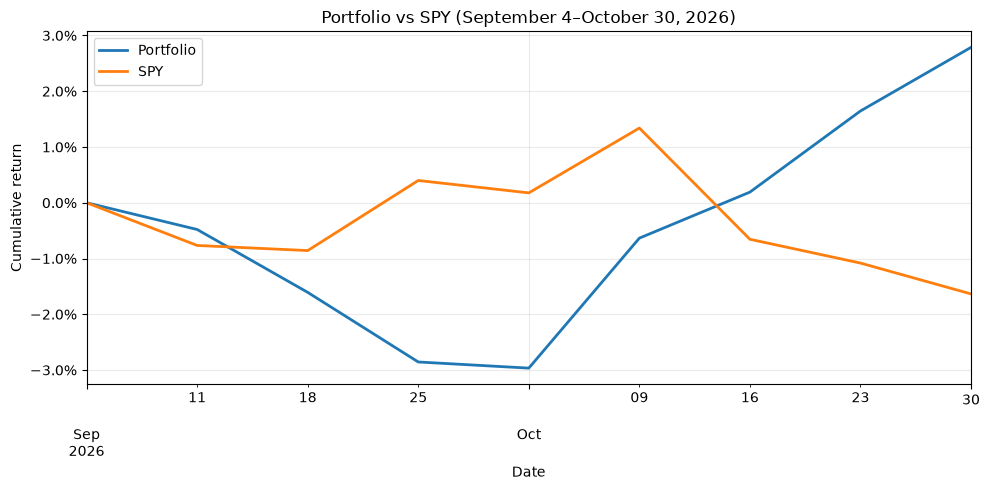

In [13]:
# Step 12: Compare cumulative performance, starting at the September 4 values.
# The portfolio starts after purchase costs; both return series start at 0%.
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

cumulative_returns = pd.DataFrame({
    "Portfolio": weekly_valuation["Portfolio ($)"] / weekly_valuation["Portfolio ($)"].iloc[0] - 1,
    "SPY": weekly_prices["SPY"] / weekly_prices["SPY"].iloc[0] - 1,
})
# SPY starts at $10 million; growth is relative to each September 4 value.
weekly_valuation_table = pd.DataFrame({
    "stock_value": weekly_valuation["Stocks ($)"],
    "cash": weekly_valuation["Cash ($)"],
    "portfolio_value": weekly_valuation["Portfolio ($)"],
    "portfolio_return": weekly_returns["Portfolio"],
    "spy_value": initial_cash * (1 + cumulative_returns["SPY"]),
    "spy_return": weekly_returns["SPY"],
    "portfolio_growth": 1 + cumulative_returns["Portfolio"],
    "spy_growth": 1 + cumulative_returns["SPY"],
}).rename_axis("date").reset_index()
display(weekly_valuation_table.style.hide(axis="index").format({
    "date": "{:%Y-%m-%d}",
    **dict.fromkeys(["stock_value", "cash", "portfolio_value", "spy_value"], "{:,.2f}"),
    **dict.fromkeys(["portfolio_return", "spy_return", "portfolio_growth", "spy_growth"], "{:.6f}"),
}, na_rep=""))

ax = cumulative_returns.plot(
    figsize=(10, 5), linewidth=2,
    title="Portfolio vs SPY (September 4–October 30, 2026)",
    xlabel="Date", ylabel="Cumulative return",
)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
